# Random Forest — Diabetes Regression

**Goal:** Predict a **continuous disease-progression measure one year after baseline**, using measurements from 442 patients.

**Important:** The scikit-learn Diabetes dataset is **regression**, not diabetes yes/no classification. Therefore we use `RandomForestRegressor`.

**Teaching sequence:** Load → Split → Baseline → Tune → Test → Interpret.  
The data is included with scikit-learn, so **no CSV download is needed**. A Random Forest does not require feature scaling.

## 1. Load the dataset

`X` has **10 features** (including age, BMI and blood-pressure-related measurements). `y` is the numeric progression score.

The input features in this built-in dataset have already been scaled; we will use them as supplied.

In [1]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

print("Rows, features:", X.shape)
print("Target range:", y.min(), "to", y.max())
display(X.head())

Rows, features: (442, 10)
Target range: 25.0 to 346.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 2. Split into training and test data

Keep 20% of the rows for the **final test**. We do not use `stratify` here because the target is continuous.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 353
Test rows: 89


## 3. Create a baseline Random Forest

Use **5-fold cross-validation on training data**. For regression, we evaluate using **R²**, not classification accuracy.

R² near 1 is better, 0 is comparable to predicting the mean of the evaluation targets, and it can be negative.

In [3]:
baseline = RandomForestRegressor(n_estimators=100, random_state=42)
baseline_scores = cross_val_score(baseline, X_train, y_train, cv=5, scoring="r2")
print("Baseline mean CV R²:", round(baseline_scores.mean(), 3))

Baseline mean CV R²: 0.391


## 4. Tune the important parameters with `GridSearchCV`

- `n_estimators`: Number of trees.
- `max_depth`: Maximum depth of each tree.
- `min_samples_leaf`: Minimum observations per leaf; a larger value makes predictions smoother.

This grid evaluates **12 combinations × 5 folds = 60 fits**. The best model is selected by its average **validation R²**.

In [4]:
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 3]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV R²:", round(grid.best_score_, 3))

Best parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV R²: 0.402


## 5. Evaluate the best model on the untouched test set

- **MAE:** Average absolute prediction error, in target units (lower is better).
- **RMSE:** Similar to MAE but penalizes large errors more (lower is better).
- **R²:** How well predictions explain variation in the target (higher is generally better).

In [5]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Test MAE: ", round(mae, 2))
print("Test RMSE:", round(rmse, 2))
print("Test R²:  ", round(r2, 3))

Test MAE:  43.56
Test RMSE: 53.68
Test R²:   0.456


## 6. Visualize actual vs predicted values

Each dot is a patient. A dot close to the diagonal indicates a prediction close to the actual value.

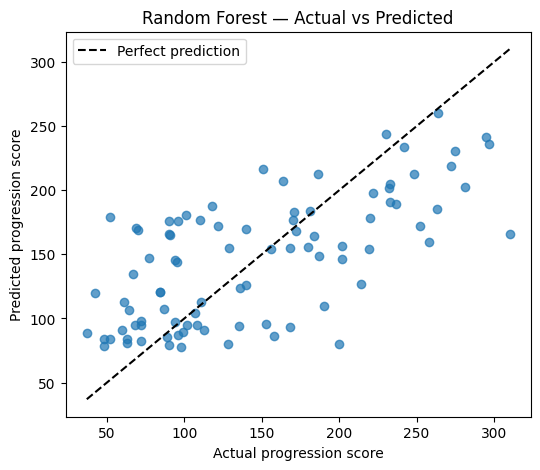

In [6]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "k--", label="Perfect prediction")
plt.xlabel("Actual progression score")
plt.ylabel("Predicted progression score")
plt.title("Random Forest — Actual vs Predicted")
plt.legend()
plt.show()

## 7. Which features did the forest use most?

The following is an interpretation aid, **not evidence of causality**.

In [7]:
importance = pd.Series(best_model.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).head(5).round(3))

bmi    0.423
s5     0.268
bp     0.078
s6     0.056
s2     0.041
dtype: float64


### Quick student checks

1. Why do we use a **regressor** rather than a classifier?
2. Why is `accuracy_score()` inappropriate for this target?
3. Why must the final test set stay out of `GridSearchCV`?

**Takeaway:** Tune using training folds, then evaluate the final regressor on a separate test set.